# EPSS / KEV Comparison

This notebook loads the `kev` and `epss_df` data frames exported by `epss_kev_loading-2.ipynb`, enforces the local `CUTOFF_DATE`, narrows the cohort to CVE-2025/2026 KEV items whose CAUSALITY `published` date is before KEV `dateAdded`, finds each CVE's high EPSS score in the 30-day window before KEV listing, and compares that score to the latest EPSS score available at the cutoff.

In [31]:
# 0. Define the analysis cutoff date -- used by cell 16 to narrow ratings_2026
# to stay consistent with the cutoff already baked into kev/epss_df by the
# loading notebook (this notebook doesn't load raw files itself).
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

ROOT = Path.cwd()
EXPORT_DIR = ROOT / "exports"
HEAD_PATH = ROOT / "HEAD"

CUTOFF_DATE = pd.Timestamp("2026-07-31")
print(f"Analysis cutoff date: {CUTOFF_DATE.date()}")

Analysis cutoff date: 2026-07-31


In [32]:
#1. Load the data for 2025/ 2026 KEV CVEs - this was prepared by the companion notebook, epss-kev-loading-2

kev = pd.read_parquet(EXPORT_DIR / "kev.parquet")
epss_df = pd.read_parquet(EXPORT_DIR / "epss_for_kev_cves.parquet")

kev["dateAdded"] = pd.to_datetime(kev["dateAdded"]).dt.normalize()
epss_df["score_date"] = pd.to_datetime(epss_df["score_date"]).dt.normalize()
epss_df = epss_df.loc[epss_df["score_date"] <= CUTOFF_DATE].copy()

# 2024 has no CAUSALITY published date, so the timed pre-KEV cohort is 2025-2026 only.
kev_timed_candidate_cves = kev.loc[
    kev["cveID"].str.startswith(("CVE-2025-", "CVE-2026-"))
    & (kev["dateAdded"] <= CUTOFF_DATE)
].copy()

print(f"Loaded kev: {len(kev):,} rows")
print(f"Loaded epss_df (EPSS for KEV CVEs, through cutoff): {len(epss_df):,} rows")
print(f"Latest EPSS score date in scope: {epss_df['score_date'].max().date()}")
print(f"Candidate KEV rows with 2025/2026 CVE IDs through {CUTOFF_DATE.date()}: {len(kev_timed_candidate_cves):,}")


Loaded kev: 285 rows
Loaded epss_df (EPSS for KEV CVEs, through cutoff): 81,106 rows
Latest EPSS score date in scope: 2026-07-31
Candidate KEV rows with 2025/2026 CVE IDs through 2026-07-31: 285


In [33]:
#2. Load published dates and ratings from CAUSALITY output files

causality_sources_for_cohort = [
    {
        "year": 2025,
        "path": HEAD_PATH / "2025-processed-clean.txt",
        "sep": ",",
    },
    {
        "year": 2026,
        "path": HEAD_PATH / "2026-august.txt",
        "sep": "	",
    },
]

published_frames_for_cohort = []

try:
    for source in causality_sources_for_cohort:
        required_cols = ["cveid", "published"]
        frame = pd.read_csv(
            source["path"],
            sep=source["sep"],
            usecols=required_cols,
            keep_default_na=False,
        )
        frame.insert(0, "year", source["year"])
        published_frames_for_cohort.append(frame)
        print(
            f"Loaded CAUSALITY {source['year']}: {len(frame):,} rows "
            f"from {source['path']}"
        )

    published_for_cohort = pd.concat(
        published_frames_for_cohort,
        ignore_index=True,
    )

    raw_published = published_for_cohort["published"].copy()
    published_for_cohort["published"] = pd.to_datetime(
        raw_published, errors="coerce"
    ).dt.tz_localize(None).dt.normalize()

    failed_published_parse = raw_published.ne("") & published_for_cohort["published"].isna()
    if failed_published_parse.any():
        bad_examples = published_for_cohort.loc[
            failed_published_parse,
            ["year", "cveid"],
        ].copy()
        bad_examples["published_raw"] = raw_published.loc[failed_published_parse]
        raise ValueError(
            "Could not parse CAUSALITY published dates. Examples:\n"
            + bad_examples.head(10).to_string(index=False)
        )

    rows_before_cutoff = len(published_for_cohort)
    after_cutoff = published_for_cohort["published"].notna() & (
        published_for_cohort["published"] > CUTOFF_DATE
    )
    published_for_cohort = published_for_cohort.loc[~after_cutoff].copy()
    rows_after_cutoff = len(published_for_cohort)

    print(f"Combined CAUSALITY published rows before cutoff: {rows_before_cutoff:,}")
    print(
        f"Rows after enforcing CUTOFF_DATE <= {CUTOFF_DATE.date()}: "
        f"{rows_after_cutoff:,}"
    )
    print(f"Rows dropped after cutoff: {rows_before_cutoff - rows_after_cutoff:,}")
    print(
        "Published date range after cutoff: "
        f"{published_for_cohort['published'].min().date()} to "
        f"{published_for_cohort['published'].max().date()}"
    )
    print(
        "Rows with missing published date: "
        f"{published_for_cohort['published'].isna().sum():,}"
    )
    print("Rows by CAUSALITY year after cutoff:")
    print(published_for_cohort["year"].value_counts().sort_index().to_string())
except FileNotFoundError as exc:
    raise FileNotFoundError(
        f"Missing CAUSALITY output file while loading published dates: {exc.filename}"
    ) from exc
except ValueError as exc:
    raise ValueError(
        "CAUSALITY published-date load failed. Check that the 2025/2026 output "
        "files exist and include cveid and published columns."
    ) from exc

# Report KEV candidates that have no CAUSALITY published date. Cell 3 only sorts
# CVEs present in published_for_cohort, so these would otherwise drop out of the
# cohort without being counted anywhere.
causality_cve_ids_all = set(pd.concat(published_frames_for_cohort, ignore_index=True)["cveid"])
kev_candidates_not_in_cohort_published = kev_timed_candidate_cves.loc[
    ~kev_timed_candidate_cves["cveID"].isin(published_for_cohort["cveid"]),
    ["cveID", "dateAdded"],
].sort_values(["dateAdded", "cveID"]).copy()
kev_candidates_not_in_cohort_published["reason"] = (
    kev_candidates_not_in_cohort_published["cveID"]
    .isin(causality_cve_ids_all)
    .map({True: "published after CUTOFF_DATE", False: "not in any CAUSALITY file"})
)

print(
    f"KEV candidate CVEs (CVE-2025/2026, dateAdded <= {CUTOFF_DATE.date()}): "
    f"{len(kev_timed_candidate_cves):,}"
)
print(
    "KEV candidate CVEs with no CAUSALITY published date (excluded from the cohort): "
    f"{len(kev_candidates_not_in_cohort_published):,}"
)
if not kev_candidates_not_in_cohort_published.empty:
    print(kev_candidates_not_in_cohort_published.to_string(index=False))

Loaded CAUSALITY 2025: 41,690 rows from z:\SHARED\GitHub\epss_scores\HEAD\2025-processed-clean.txt
Loaded CAUSALITY 2026: 38,962 rows from z:\SHARED\GitHub\epss_scores\HEAD\2026-august.txt
Combined CAUSALITY published rows before cutoff: 80,652
Rows after enforcing CUTOFF_DATE <= 2026-07-31: 80,298
Rows dropped after cutoff: 354
Published date range after cutoff: 2025-01-01 to 2026-07-31
Rows with missing published date: 0
Rows by CAUSALITY year after cutoff:
year
2025    41690
2026    38608
KEV candidate CVEs (CVE-2025/2026, dateAdded <= 2026-07-31): 285
KEV candidate CVEs with no CAUSALITY published date (excluded from the cohort): 2
         cveID  dateAdded                    reason
CVE-2025-48595 2026-06-02 not in any CAUSALITY file
CVE-2025-67038 2026-06-23 not in any CAUSALITY file


In [34]:
#3. Filter to exclude same-day KEV additions - a CVE that was not published prior to listing cannot be predicted 

kev_date_added_by_cve = kev_timed_candidate_cves.set_index("cveID")["dateAdded"]

published_for_cohort = published_for_cohort.loc[
    published_for_cohort["cveid"].isin(kev_timed_candidate_cves["cveID"])
].copy()

if published_for_cohort["cveid"].duplicated().any():
    duplicates = published_for_cohort.loc[
        published_for_cohort["cveid"].duplicated(keep=False), "cveid"
    ].sort_values().tolist()
    raise ValueError(f"Duplicate CAUSALITY published rows for KEV CVEs: {duplicates[:20]}")

published_for_cohort["dateAdded"] = published_for_cohort["cveid"].map(kev_date_added_by_cve)

published_for_cohort["date_comparison"] = "missing published or dateAdded"
published_for_cohort.loc[
    published_for_cohort["published"].notna()
    & published_for_cohort["dateAdded"].notna()
    & (published_for_cohort["published"] < published_for_cohort["dateAdded"]),
    "date_comparison",
] = "published before dateAdded"
published_for_cohort.loc[
    published_for_cohort["published"].notna()
    & published_for_cohort["dateAdded"].notna()
    & (published_for_cohort["published"] == published_for_cohort["dateAdded"]),
    "date_comparison",
] = "published same day as dateAdded"
published_for_cohort.loc[
    published_for_cohort["published"].notna()
    & published_for_cohort["dateAdded"].notna()
    & (published_for_cohort["published"] > published_for_cohort["dateAdded"]),
    "date_comparison",
] = "published after dateAdded"

comparison_cols = ["year", "cveid", "published", "dateAdded", "date_comparison"]
same_day_published_rows = published_for_cohort.loc[
    published_for_cohort["published"].eq(published_for_cohort["dateAdded"]),
    comparison_cols,
].sort_values(["dateAdded", "cveid"])
not_same_day_published_rows = published_for_cohort.loc[
    published_for_cohort["published"].ne(published_for_cohort["dateAdded"]),
    comparison_cols,
].sort_values(["date_comparison", "dateAdded", "cveid"])
kev_before_publication_rows = published_for_cohort.loc[
    published_for_cohort["published"].notna()
    & published_for_cohort["dateAdded"].notna()
    & (published_for_cohort["dateAdded"] < published_for_cohort["published"]),
    comparison_cols,
].sort_values(["dateAdded", "cveid"])
kev_before_publication_rows["days_publication_after_kev"] = (
    kev_before_publication_rows["published"] - kev_before_publication_rows["dateAdded"]
).dt.days

print("CAUSALITY published date vs KEV dateAdded comparison:")
print(published_for_cohort["date_comparison"].value_counts().reindex([
    "published before dateAdded",
    "published same day as dateAdded",
    "published after dateAdded",
    "missing published or dateAdded",
], fill_value=0).to_string())

same_day_published_count = len(same_day_published_rows)
print(
    "Rows where CAUSALITY published date equals KEV dateAdded: "
    f"{same_day_published_count:,}"
)
display(same_day_published_rows)

print(f"Rows where published != dateAdded: {len(not_same_day_published_rows):,}")
display(not_same_day_published_rows)

print(
    "Rows where KEV dateAdded is before the CAUSALITY/NVD published date: "
    f"{len(kev_before_publication_rows):,}"
)
display(kev_before_publication_rows)

published_before_date_added_count = (
    published_for_cohort["date_comparison"].eq("published before dateAdded").sum()
)
published_before_kev_cve_ids = set(
    published_for_cohort.loc[
        published_for_cohort["date_comparison"].eq("published before dateAdded"),
        "cveid",
    ]
)
candidates = kev_timed_candidate_cves.loc[
    kev_timed_candidate_cves["cveID"].isin(published_before_kev_cve_ids)
].copy()

if len(candidates) != published_before_date_added_count:
    raise ValueError(
        "Candidate row count does not match published-before-dateAdded count: "
        f"candidates={len(candidates):,}, "
        f"published_before_dateAdded={published_before_date_added_count:,}"
    )

kev_recent_cves = candidates.copy()

kev_after_publication_count = len(candidates)
print(f"KEV rows published before KEV dateAdded: {kev_after_publication_count:,}")
print(candidates["cveID"].str.extract(r"CVE-(\d{4})-", expand=False).value_counts().sort_index().to_string())
print(
    "Summary: rows where KEV dateAdded is after the CAUSALITY/NVD published date: "
    f"{kev_after_publication_count:,}"
)
print(
    "Candidate row-count check passed: "
    f"candidates={len(candidates):,}; "
    f"published before dateAdded={published_before_date_added_count:,}"
)


CAUSALITY published date vs KEV dateAdded comparison:
date_comparison
published before dateAdded         204
published same day as dateAdded     72
published after dateAdded            7
missing published or dateAdded       0
Rows where CAUSALITY published date equals KEV dateAdded: 72


,year,cveid,published,dateAdded,date_comparison
217,2025,CVE-2025-0282,2025-01-08,2025-01-08,published same day as dateAdded
7477,2025,CVE-2025-21333,2025-01-14,2025-01-14,published same day as dateAdded
7478,2025,CVE-2025-21334,2025-01-14,2025-01-14,published same day as dateAdded
7479,2025,CVE-2025-21335,2025-01-14,2025-01-14,published same day as dateAdded
7533,2025,CVE-2025-21391,2025-02-11,2025-02-11,published same day as dateAdded
...,...,...,...,...,...
71938,2026,CVE-2026-56155,2026-07-14,2026-07-14,published same day as dateAdded
71944,2026,CVE-2026-56164,2026-07-14,2026-07-14,published same day as dateAdded
46272,2026,CVE-2026-16232,2026-07-22,2026-07-22,published same day as dateAdded
46495,2026,CVE-2026-16812,2026-07-27,2026-07-27,published same day as dateAdded


Rows where published != dateAdded: 211


,year,cveid,published,dateAdded,date_comparison
40657,2025,CVE-2025-8875,2025-08-14,2025-08-13,published after dateAdded
40658,2025,CVE-2025-8876,2025-08-14,2025-08-13,published after dateAdded
1320,2025,CVE-2025-10585,2025-09-24,2025-09-23,published after dateAdded
24478,2025,CVE-2025-48572,2025-12-08,2025-12-02,published after dateAdded
24535,2025,CVE-2025-48633,2025-12-08,2025-12-02,published after dateAdded
...,...,...,...,...,...
42200,2026,CVE-2026-0770,2026-01-23,2026-07-21,published before dateAdded
74515,2026,CVE-2026-60137,2026-07-17,2026-07-21,published before dateAdded
75795,2026,CVE-2026-63030,2026-07-17,2026-07-21,published before dateAdded
69744,2026,CVE-2026-50522,2026-07-14,2026-07-22,published before dateAdded


Rows where KEV dateAdded is before the CAUSALITY/NVD published date: 7


,year,cveid,published,dateAdded,date_comparison,days_publication_after_kev
40657,2025,CVE-2025-8875,2025-08-14,2025-08-13,published after dateAdded,1
40658,2025,CVE-2025-8876,2025-08-14,2025-08-13,published after dateAdded,1
1320,2025,CVE-2025-10585,2025-09-24,2025-09-23,published after dateAdded,1
24478,2025,CVE-2025-48572,2025-12-08,2025-12-02,published after dateAdded,6
24535,2025,CVE-2025-48633,2025-12-08,2025-12-02,published after dateAdded,6
21922,2025,CVE-2025-43529,2025-12-17,2025-12-15,published after dateAdded,2
20869,2025,CVE-2025-40602,2025-12-18,2025-12-17,published after dateAdded,1


KEV rows published before KEV dateAdded: 204
cveID
2025    134
2026     70
Summary: rows where KEV dateAdded is after the CAUSALITY/NVD published date: 204
Candidate row-count check passed: candidates=204; published before dateAdded=204


In [35]:
# 4. Find the most recent EPSS score within 30 days before KEV listing
# Matches only candidates: CVE-2025/2026 KEV items whose CAUSALITY/NVD
# published date is before KEV dateAdded.
# Uses an as-of backward lookup: the most recent score_date strictly before
# dateAdded, bounded to 30 days before dateAdded. This preserves the intended
# pre-KEV window without requiring an exact dateAdded - 1 day row.

PRIOR_EPSS_WINDOW = pd.Timedelta(days=30)
epss_for_candidate_cves = epss_df.loc[
    epss_df["cve"].isin(candidates["cveID"].unique().tolist())
].copy()
# merge_asof requires matching key dtypes; a parquet round-trip can leave
# score_date at a different datetime resolution than dateAdded.
epss_for_candidate_cves["score_date"] = epss_for_candidate_cves["score_date"].astype("datetime64[ns]")

candidates_sorted_by_date_added = candidates.sort_values("dateAdded")
epss_sorted_by_score_date = epss_for_candidate_cves.sort_values("score_date")

# Most recent score strictly before dateAdded, no more than 30 days earlier.
strict_prior_match = pd.merge_asof(
    candidates_sorted_by_date_added,
    epss_sorted_by_score_date,
    left_on="dateAdded",
    right_on="score_date",
    left_by="cveID",
    right_by="cve",
    direction="backward",
    allow_exact_matches=False,
    tolerance=PRIOR_EPSS_WINDOW,
)

kev_epss_day_before_added = strict_prior_match.copy()
kev_epss_day_before_added["used_same_day_fallback"] = False
kev_epss_day_before_added = kev_epss_day_before_added.drop(columns=["cve"])

kev_epss_day_before_added = kev_epss_day_before_added.rename(columns={
    "score_date": "epss_score_date_before_added",
    "epss": "epss_day_before_added",
    "percentile": "epss_percentile_day_before_added",
})
kev_epss_day_before_added["had_epss_score_day_before_added"] = (
    kev_epss_day_before_added["epss_day_before_added"].notna()
)
kev_epss_day_before_added["days_before_added"] = (
    kev_epss_day_before_added["dateAdded"] - kev_epss_day_before_added["epss_score_date_before_added"]
).dt.days

if len(kev_epss_day_before_added) != len(candidates):
    raise ValueError(
        "EPSS prior-score check row count does not match candidates: "
        f"matched={len(kev_epss_day_before_added):,}, candidates={len(candidates):,}"
    )

print(f"EPSS rows for candidate CVEs only: {len(epss_for_candidate_cves):,}")
print(f"Candidate KEV CVEs checked for a prior EPSS score: {len(kev_epss_day_before_added):,}")
print(f"Candidate KEV CVEs WITH a usable EPSS score within 30 days before dateAdded: {kev_epss_day_before_added['had_epss_score_day_before_added'].sum():,}")
print(f"  Same-day EPSS scores used: {kev_epss_day_before_added['used_same_day_fallback'].sum():,}")
print(f"Candidate KEV CVEs with NO usable EPSS score in the 30-day pre-KEV window: {(~kev_epss_day_before_added['had_epss_score_day_before_added']).sum():,}")
_found = kev_epss_day_before_added.loc[kev_epss_day_before_added["had_epss_score_day_before_added"], "days_before_added"]
print(f"Of those, more than 1 day before dateAdded: {(_found > 1).sum():,}")
print(f"Of those, more than 30 days before dateAdded: {(_found > 30).sum():,}")

EPSS rows for candidate CVEs only: 58,862
Candidate KEV CVEs checked for a prior EPSS score: 204
Candidate KEV CVEs WITH a usable EPSS score within 30 days before dateAdded: 182
  Same-day EPSS scores used: 0
Candidate KEV CVEs with NO usable EPSS score in the 30-day pre-KEV window: 22
Of those, more than 1 day before dateAdded: 0
Of those, more than 30 days before dateAdded: 0


In [36]:
# 5. Find the highest EPSS score within 30 days before KEV listing
# This uses the candidate cohort and the same strict pre-KEV window as cell 4,
# but picks the maximum EPSS score in that window rather than the most recent score.
candidate_windows = candidates[["cveID", "dateAdded"]].copy()
candidate_windows["kev_window_start"] = candidate_windows["dateAdded"] - PRIOR_EPSS_WINDOW

epss_pre_kev_window = epss_for_candidate_cves.merge(
    candidate_windows,
    left_on="cve",
    right_on="cveID",
    how="inner",
    validate="many_to_one",
)
epss_pre_kev_window = epss_pre_kev_window.loc[
    (epss_pre_kev_window["score_date"] < epss_pre_kev_window["dateAdded"])
    & (epss_pre_kev_window["score_date"] >= epss_pre_kev_window["kev_window_start"])
].copy()

highest_epss_before_kev = (
    epss_pre_kev_window.sort_values(
        ["cve", "epss", "score_date"],
        ascending=[True, False, False],
    )
    .drop_duplicates("cve", keep="first")
    [["cve", "score_date", "epss", "percentile"]]
    .rename(columns={
        "cve": "cveID",
        "score_date": "highest_epss_score_date_before_added",
        "epss": "highest_epss_before_added",
        "percentile": "highest_epss_percentile_before_added",
    })
)

candidate_highest_epss_before_kev = candidates.merge(
    highest_epss_before_kev,
    on="cveID",
    how="left",
    validate="one_to_one",
)
candidate_highest_epss_before_kev["had_highest_epss_before_added"] = (
    candidate_highest_epss_before_kev["highest_epss_before_added"].notna()
)
candidate_highest_epss_before_kev["days_before_added_at_highest_epss"] = (
    candidate_highest_epss_before_kev["dateAdded"]
    - candidate_highest_epss_before_kev["highest_epss_score_date_before_added"]
).dt.days

if len(candidate_highest_epss_before_kev) != len(candidates):
    raise ValueError(
        "Highest pre-KEV EPSS row count does not match candidates: "
        f"highest_pre_kev={len(candidate_highest_epss_before_kev):,}, "
        f"candidates={len(candidates):,}"
    )

print(
    "Candidate CVEs checked for highest EPSS score within 30 days before dateAdded: "
    f"{len(candidate_highest_epss_before_kev):,}"
)
print(
    "Candidate CVEs WITH a usable highest EPSS score in the 30-day pre-KEV window: "
    f"{candidate_highest_epss_before_kev['had_highest_epss_before_added'].sum():,}"
)
print(
    "Candidate CVEs with NO usable EPSS score in the 30-day pre-KEV window: "
    f"{(~candidate_highest_epss_before_kev['had_highest_epss_before_added']).sum():,}"
)
_found_highest = candidate_highest_epss_before_kev.loc[
    candidate_highest_epss_before_kev["had_highest_epss_before_added"],
    "days_before_added_at_highest_epss",
]
print(f"Of those, more than 30 days before dateAdded: {(_found_highest > 30).sum():,}")

#display(candidate_highest_epss_before_kev)


Candidate CVEs checked for highest EPSS score within 30 days before dateAdded: 204
Candidate CVEs WITH a usable highest EPSS score in the 30-day pre-KEV window: 182
Candidate CVEs with NO usable EPSS score in the 30-day pre-KEV window: 22
Of those, more than 30 days before dateAdded: 0


In [37]:
# 4c. Find the highest EPSS percentile within 30 days before KEV listing
# Uses the same 30-day pre-KEV window rows as cell 4b (epss_pre_kev_window), but
# picks each CVE's maximum percentile independently of its maximum score. The
# percentile can peak on a different day than the score because it is relative
# to all CVEs scored that day.

highest_percentile_before_kev = (
    epss_pre_kev_window.sort_values(
        ["cve", "percentile", "score_date"],
        ascending=[True, False, False],
    )
    .drop_duplicates("cve", keep="first")
    [["cve", "score_date", "percentile", "epss"]]
    .rename(columns={
        "cve": "cveID",
        "score_date": "highest_percentile_score_date_before_added",
        "percentile": "highest_percentile_before_added",
        "epss": "epss_at_highest_percentile_before_added",
    })
)

candidate_highest_score_and_percentile_before_kev = candidate_highest_epss_before_kev.merge(
    highest_percentile_before_kev,
    on="cveID",
    how="left",
    validate="one_to_one",
)
candidate_highest_score_and_percentile_before_kev["had_highest_percentile_before_added"] = (
    candidate_highest_score_and_percentile_before_kev["highest_percentile_before_added"].notna()
)
candidate_highest_score_and_percentile_before_kev["days_before_added_at_highest_percentile"] = (
    candidate_highest_score_and_percentile_before_kev["dateAdded"]
    - candidate_highest_score_and_percentile_before_kev["highest_percentile_score_date_before_added"]
).dt.days

if len(candidate_highest_score_and_percentile_before_kev) != len(candidates):
    raise ValueError(
        "Highest pre-KEV percentile row count does not match candidates: "
        f"highest_percentile={len(candidate_highest_score_and_percentile_before_kev):,}, "
        f"candidates={len(candidates):,}"
    )

# The same window rows feed 4b and 4c, so the CVEs with no score must match exactly.
_no_score = candidate_highest_score_and_percentile_before_kev
if not _no_score["had_highest_percentile_before_added"].equals(_no_score["had_highest_epss_before_added"]):
    raise ValueError("CVEs missing a pre-KEV percentile do not match CVEs missing a pre-KEV score (cell 4b).")

_has = _no_score.loc[_no_score["had_highest_percentile_before_added"]]
_peak_pct_differs = (
    _has["highest_percentile_before_added"] > _has["highest_epss_percentile_before_added"]
)
_peak_day_differs = (
    _has["highest_percentile_score_date_before_added"]
    != _has["highest_epss_score_date_before_added"]
)

print(
    "Candidate CVEs checked for highest EPSS percentile within 30 days before dateAdded: "
    f"{len(candidate_highest_score_and_percentile_before_kev):,}"
)
print(
    "Candidate CVEs WITH a highest percentile in the 30-day pre-KEV window: "
    f"{candidate_highest_score_and_percentile_before_kev['had_highest_percentile_before_added'].sum():,}"
)
print(
    "Candidate CVEs with NO usable EPSS score in the 30-day pre-KEV window: "
    f"{(~candidate_highest_score_and_percentile_before_kev['had_highest_percentile_before_added']).sum():,}"
)
print(f"Of those with a score, peak percentile on a different day than peak score: {_peak_day_differs.sum():,}")
print(f"Of those with a score, peak percentile higher than percentile on peak-score day: {_peak_pct_differs.sum():,}")

display(candidate_highest_score_and_percentile_before_kev[[
    "cveID",
    "dateAdded",
    "highest_epss_before_added",
    "highest_epss_score_date_before_added",
    "highest_epss_percentile_before_added",
    "highest_percentile_before_added",
    "highest_percentile_score_date_before_added",
    "epss_at_highest_percentile_before_added",
]].sort_values("highest_percentile_before_added", ascending=False))

Candidate CVEs checked for highest EPSS percentile within 30 days before dateAdded: 204
Candidate CVEs WITH a highest percentile in the 30-day pre-KEV window: 182
Candidate CVEs with NO usable EPSS score in the 30-day pre-KEV window: 22
Of those with a score, peak percentile on a different day than peak score: 74
Of those with a score, peak percentile higher than percentile on peak-score day: 74


,cveID,dateAdded,highest_epss_before_added,highest_epss_score_date_before_added,highest_epss_percentile_before_added,highest_percentile_before_added,highest_percentile_score_date_before_added,epss_at_highest_percentile_before_added
117,CVE-2025-24893,2025-10-30,0.93998,2025-10-29,0.99883,0.99890,2025-10-03,0.93998
80,CVE-2025-49113,2026-02-20,0.92106,2026-02-19,0.99697,0.99697,2026-02-19,0.92106
186,CVE-2025-24813,2025-04-01,0.88822,2025-03-31,0.99493,0.99493,2025-03-31,0.88822
174,CVE-2025-3248,2025-05-05,0.84184,2025-05-04,0.99243,0.99252,2025-05-03,0.84184
63,CVE-2025-32432,2026-03-20,0.82912,2026-03-01,0.99236,0.99236,2026-03-01,0.82912
...,...,...,...,...,...,...,...,...
185,CVE-2025-22457,2025-04-04,NaN,NaT,NaN,NaN,NaT,NaN
187,CVE-2025-2783,2025-03-27,NaN,NaT,NaN,NaN,NaT,NaN
192,CVE-2025-21590,2025-03-13,NaN,NaT,NaN,NaN,NaT,NaN
200,CVE-2025-0994,2025-02-07,NaN,NaT,NaN,NaN,NaT,NaN


In [38]:
# 6. Find the current/latest EPSS score for candidate KEV CVEs

latest_score_date = epss_df["score_date"].max()

latest_epss_for_candidate_cves = epss_df.loc[
    (epss_df["score_date"] == latest_score_date)
    & epss_df["cve"].isin(candidates["cveID"].unique().tolist())
].rename(columns={
    "score_date": "latest_score_date",
    "epss": "epss_latest",
    "percentile": "epss_percentile_latest",
})

kev_epss_day_before_vs_latest = kev_epss_day_before_added.merge(
    latest_epss_for_candidate_cves,
    left_on="cveID",
    right_on="cve",
    how="left",
    validate="one_to_one",
).drop(columns=["cve"])

if len(kev_epss_day_before_vs_latest) != len(candidates):
    raise ValueError(
        "Latest EPSS comparison row count does not match candidates: "
        f"comparison={len(kev_epss_day_before_vs_latest):,}, candidates={len(candidates):,}"
    )

kev_epss_day_before_vs_latest["epss_delta_latest_minus_day_before"] = (
    kev_epss_day_before_vs_latest["epss_latest"]
    - kev_epss_day_before_vs_latest["epss_day_before_added"]
)

def latest_score_direction(row):
    if pd.isna(row["epss_latest"]):
        return "no current EPSS score"
    if not row["had_epss_score_day_before_added"]:
        return "no 30-day pre-KEV EPSS score"
    delta = row["epss_delta_latest_minus_day_before"]
    if delta > 0:
        return "higher"
    if delta < 0:
        return "lower"
    return "same"

kev_epss_day_before_vs_latest["epss_direction"] = kev_epss_day_before_vs_latest.apply(
    latest_score_direction, axis=1
)

print(f"Latest EPSS score date: {latest_score_date.date()}")
print(f"Latest EPSS rows for candidate CVEs: {len(latest_epss_for_candidate_cves):,}")
print(f"Candidate KEV CVEs compared with latest EPSS: {len(kev_epss_day_before_vs_latest):,}")
print(kev_epss_day_before_vs_latest["epss_direction"].value_counts().to_string())

Latest EPSS score date: 2026-07-31
Latest EPSS rows for candidate CVEs: 204
Candidate KEV CVEs compared with latest EPSS: 204
epss_direction
higher                          182
no 30-day pre-KEV EPSS score     22


In [39]:
# 5b. For KEV CVEs with no 30-day pre-KEV EPSS score, find when their first EPSS score appeared

kev_cves_missing_day_before_score = kev_epss_day_before_added.loc[
    ~kev_epss_day_before_added["had_epss_score_day_before_added"],
    ["cveID", "dateAdded"],
].copy()

first_epss_score_by_cve = (
    epss_for_candidate_cves.groupby("cve")["score_date"]
    .min()
    .rename("first_epss_score_date")
    .reset_index()
)

kev_missing_day_before_first_score = kev_cves_missing_day_before_score.merge(
    first_epss_score_by_cve,
    left_on="cveID",
    right_on="cve",
    how="left",
    validate="one_to_one",
).drop(columns=["cve"])

# Attach the CAUSALITY published date so the table shows how long each CVE
# had been public before KEV listing.
kev_missing_day_before_first_score.insert(
    1,
    "published",
    kev_missing_day_before_first_score["cveID"].map(
        published_for_cohort.set_index("cveid")["published"]
    ),
)
kev_missing_day_before_first_score.insert(
    3,
    "days_published_to_kev",
    (
        kev_missing_day_before_first_score["dateAdded"]
        - kev_missing_day_before_first_score["published"]
    ).dt.days,
)

kev_missing_day_before_first_score["days_published_to_first_score"] = (
    kev_missing_day_before_first_score["first_epss_score_date"]
    - kev_missing_day_before_first_score["published"]
).dt.days

kev_missing_day_before_first_score["days_after_kev_added"] = (
    kev_missing_day_before_first_score["first_epss_score_date"]
    - kev_missing_day_before_first_score["dateAdded"]
).dt.days

print(f"Candidate KEV CVEs with no 30-day pre-KEV EPSS score: {len(kev_missing_day_before_first_score):,}")
print(
    "Of those, with no EPSS score at all in the loaded 2025-2026 cutoff data: "
    f"{kev_missing_day_before_first_score['first_epss_score_date'].isna().sum():,}"
)
print("Days from publication to KEV listing:")
print(kev_missing_day_before_first_score["days_published_to_kev"].value_counts().sort_index().to_string())
display(kev_missing_day_before_first_score.sort_values("dateAdded", ascending=False))

Candidate KEV CVEs with no 30-day pre-KEV EPSS score: 22
Of those, with no EPSS score at all in the loaded 2025-2026 cutoff data: 0
Days from publication to KEV listing:
days_published_to_kev
1    22


,cveID,published,dateAdded,days_published_to_kev,first_epss_score_date,days_published_to_first_score,days_after_kev_added
21,CVE-2026-56291,2026-07-09,2026-07-10,1,2026-07-10,1,0
20,CVE-2026-11645,2026-06-08,2026-06-09,1,2026-06-09,1,0
19,CVE-2026-28318,2026-06-04,2026-06-05,1,2026-06-05,1,0
18,CVE-2026-42897,2026-05-14,2026-05-15,1,2026-05-15,1,0
17,CVE-2026-41940,2026-04-29,2026-04-30,1,2026-04-30,1,0
16,CVE-2026-3909,2026-03-12,2026-03-13,1,2026-03-13,1,0
15,CVE-2026-3910,2026-03-12,2026-03-13,1,2026-03-13,1,0
14,CVE-2026-21385,2026-03-02,2026-03-03,1,2026-03-03,1,0
13,CVE-2026-22769,2026-02-17,2026-02-18,1,2026-02-18,1,0
12,CVE-2026-20700,2026-02-11,2026-02-12,1,2026-02-12,1,0


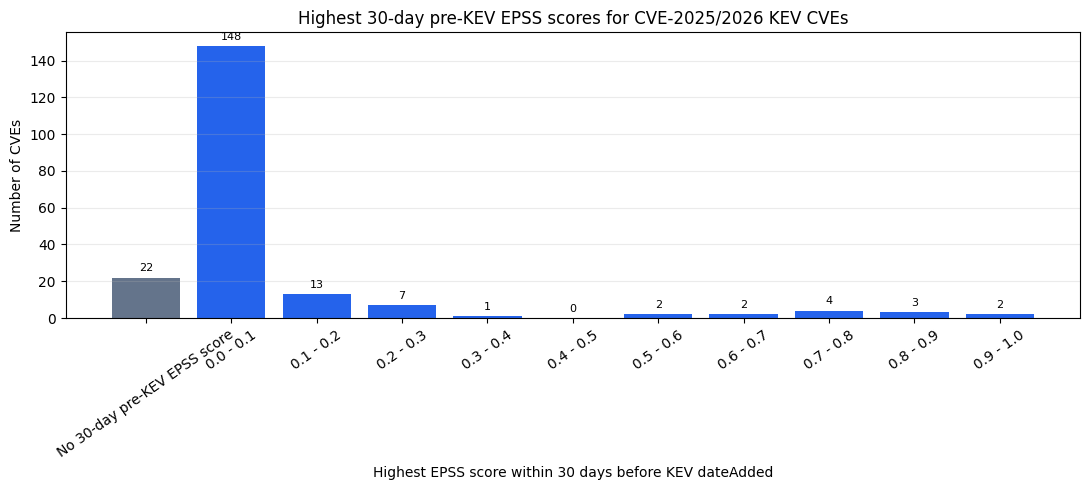

Plotted 204 KEV CVEs.
Missing 30-day pre-KEV EPSS scores in separate bin: 22


In [40]:
# 7. Plot highest 30-day pre-KEV EPSS scores for KEV CVEs in 10 bins, with missing scores in their own bin

# Reuse the highest-score lookup already computed in cell 4b, scoped to candidates.
highest_epss_prior_kev = candidate_highest_epss_before_kev.rename(columns={
    "had_highest_epss_before_added": "had_prior_kev_highest_epss_score",
})

# Use a tiny extension only on the final edge so a valid score of 1.0 is
# included in the displayed 0.9 - 1.0 bin.
highest_bin_edges = [i / 10 for i in range(10)] + [1.000001]
highest_bin_labels = [f"{i / 10:.1f} - {(i + 1) / 10:.1f}" for i in range(10)]
highest_score_bins = pd.cut(
    highest_epss_prior_kev.loc[
        highest_epss_prior_kev["had_prior_kev_highest_epss_score"],
        "highest_epss_before_added",
    ],
    bins=highest_bin_edges,
    labels=highest_bin_labels,
    include_lowest=True,
    right=False,
).value_counts(sort=False)

highest_prior_kev_epss_bins = pd.concat([
    pd.Series({"No 30-day pre-KEV EPSS score": (~highest_epss_prior_kev["had_prior_kev_highest_epss_score"]).sum()}),
    highest_score_bins,
]).rename_axis("highest_epss_before_added_bin").reset_index(name="cve_count")
highest_prior_kev_epss_bins["pct"] = (
    highest_prior_kev_epss_bins["cve_count"] / len(highest_epss_prior_kev) * 100
).round(1)

#display(highest_prior_kev_epss_bins)

fig, ax = plt.subplots(figsize=(11, 5))
labels = highest_prior_kev_epss_bins["highest_epss_before_added_bin"].astype(str)
counts = highest_prior_kev_epss_bins["cve_count"]
bars = ax.bar(labels, counts, color=["#64748b"] + ["#2563eb"] * 10)
ax.bar_label(bars, labels=[str(int(c)) for c in counts], padding=3, fontsize=8)
ax.set_title("Highest 30-day pre-KEV EPSS scores for CVE-2025/2026 KEV CVEs")
ax.set_xlabel("Highest EPSS score within 30 days before KEV dateAdded")
ax.set_ylabel("Number of CVEs")
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

print(f"Plotted {len(highest_epss_prior_kev):,} KEV CVEs.")
print(
    "Missing 30-day pre-KEV EPSS scores in separate bin: "
    f"{(~highest_epss_prior_kev['had_prior_kev_highest_epss_score']).sum():,}"
)


In [41]:
# 8. Color configuration for the four fixed EPSS score bins
# Change the hex values here; all fixed-bin bar charts and pie charts use them.
FIXED_BIN_COLORS = {
    "No 30-day pre-KEV EPSS score": "#94a3b8",
    "0.00 - 0.25": "#2563eb",
    ">0.25 - 0.50": "#facc15",
    ">0.50 - 0.75": "#dc2626",
    ">0.75 - 1.00": "#dc2626",
}


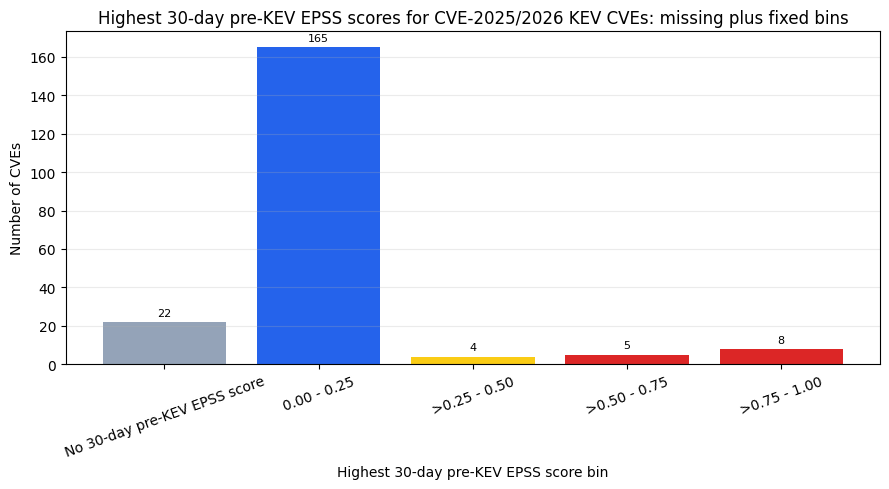

Plotted 204 KEV CVEs.
Missing 30-day pre-KEV EPSS scores in separate bin: 22


In [42]:
# 9. Plot highest 30-day pre-KEV EPSS scores in 5 bins: missing plus fixed score range
# This cell expects highest_epss_prior_kev from the high-score plotting cell.

highest_actual_scores = highest_epss_prior_kev.loc[
    highest_epss_prior_kev["had_prior_kev_highest_epss_score"],
    "highest_epss_before_added",
]

fixed_bins = [0.0, 0.25, 0.50, 0.75, 1.000001]
fixed_labels = ["0.00 - 0.25", ">0.25 - 0.50", ">0.50 - 0.75", ">0.75 - 1.00"]
highest_score_counts = pd.cut(
    highest_actual_scores,
    bins=fixed_bins,
    labels=fixed_labels,
    include_lowest=True,
    right=True,
).value_counts(sort=False)

highest_prior_kev_fixed_bins = pd.concat([
    pd.Series({"No 30-day pre-KEV EPSS score": (~highest_epss_prior_kev["had_prior_kev_highest_epss_score"]).sum()}),
    highest_score_counts,
]).rename_axis("highest_epss_before_added_bin").reset_index(name="cve_count")
highest_prior_kev_fixed_bins["pct"] = (
    highest_prior_kev_fixed_bins["cve_count"] / len(highest_epss_prior_kev) * 100
).round(1)

#display(highest_prior_kev_fixed_bins)

fig, ax = plt.subplots(figsize=(9, 5))
labels = highest_prior_kev_fixed_bins["highest_epss_before_added_bin"].astype(str)
counts = highest_prior_kev_fixed_bins["cve_count"]
bar_colors = [FIXED_BIN_COLORS[label] for label in labels]
bars = ax.bar(labels, counts, color=bar_colors)
ax.bar_label(bars, labels=[str(int(c)) for c in counts], padding=3, fontsize=8)
ax.set_title("Highest 30-day pre-KEV EPSS scores for CVE-2025/2026 KEV CVEs: missing plus fixed bins")
ax.set_xlabel("Highest 30-day pre-KEV EPSS score bin")
ax.set_ylabel("Number of CVEs")
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print(f"Plotted {len(highest_epss_prior_kev):,} KEV CVEs.")
print(
    "Missing 30-day pre-KEV EPSS scores in separate bin: "
    f"{(~highest_epss_prior_kev['had_prior_kev_highest_epss_score']).sum():,}"
)


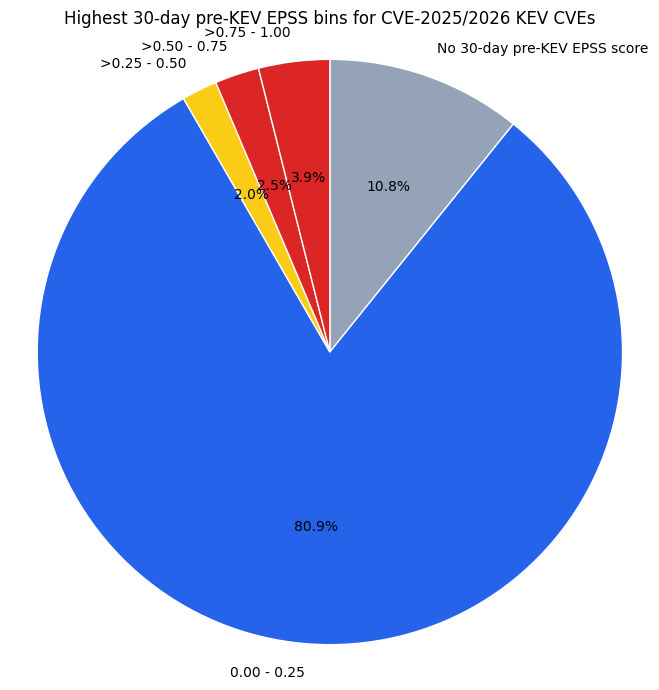

In [43]:
# 10. Pie chart of highest 30-day pre-KEV EPSS scores using fixed bins
# This cell expects highest_prior_kev_fixed_bins from cell 7.

highest_pie_data = highest_prior_kev_fixed_bins.copy()

highest_pie_colors = [
    FIXED_BIN_COLORS[label]
    for label in highest_pie_data["highest_epss_before_added_bin"].astype(str)
]

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    highest_pie_data["cve_count"],
    labels=highest_pie_data["highest_epss_before_added_bin"],
    autopct=lambda pct: f"{pct:.1f}%",
    startangle=90,
    counterclock=False,
    colors=highest_pie_colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1},
)
ax.set_title("Highest 30-day pre-KEV EPSS bins for CVE-2025/2026 KEV CVEs")
ax.axis("equal")

plt.tight_layout()
plt.show()

#display(highest_pie_data)


In [44]:
# 11. Table of highest 30-day pre-KEV EPSS scores using fixed bins (same data as the cell 8 pie)
# This cell expects highest_prior_kev_fixed_bins from cell 7.

highest_table = highest_prior_kev_fixed_bins.rename(columns={
    "highest_epss_before_added_bin": "Highest 30-day pre-KEV EPSS",
    "cve_count": "CVEs",
    "pct": "% of CVEs",
}).copy()
highest_table["Highest 30-day pre-KEV EPSS"] = highest_table["Highest 30-day pre-KEV EPSS"].astype(str)

highest_table_total = pd.DataFrame([{
    "Highest 30-day pre-KEV EPSS": "Total",
    "CVEs": highest_table["CVEs"].sum(),
    "% of CVEs": round(highest_table["CVEs"].sum() / len(highest_epss_prior_kev) * 100, 1),
}])
highest_table = pd.concat([highest_table, highest_table_total], ignore_index=True)


def _bin_swatch(label):
    color = FIXED_BIN_COLORS.get(label)
    return f"border-left: 6px solid {color}" if color else "font-weight: bold"


display(
    highest_table.style
    .hide(axis="index")
    .format({"CVEs": "{:,}", "% of CVEs": "{:.1f}%"})
    .map(_bin_swatch, subset=["Highest 30-day pre-KEV EPSS"])
    .set_caption("Highest 30-day pre-KEV EPSS bins for CVE-2025/2026 KEV CVEs")
)

Highest 30-day pre-KEV EPSS,CVEs,% of CVEs
No 30-day pre-KEV EPSS score,22,10.8%
0.00 - 0.25,165,80.9%
>0.25 - 0.50,4,2.0%
>0.50 - 0.75,5,2.5%
>0.75 - 1.00,8,3.9%
Total,204,100.0%


In [45]:
# 12. Tables of highest 30-day pre-KEV EPSS score and highest 30-day pre-KEV EPSS percentile
# This cell expects candidate_highest_score_and_percentile_before_kev from cell 4c
# and FIXED_BIN_COLORS from the color configuration cell. Score and percentile
# maxima are taken independently within the same 30-day pre-KEV window.

score_pct_source = candidate_highest_score_and_percentile_before_kev
score_pct_total = len(score_pct_source)
NO_SCORE_LABEL = "No 30-day pre-KEV EPSS score"

# Score bins match cell 7: 0.00 - 0.25, >0.25 - 0.50, >0.50 - 0.75, >0.75 - 1.00
score_bin_counts = pd.cut(
    score_pct_source.loc[score_pct_source["had_highest_epss_before_added"], "highest_epss_before_added"],
    bins=fixed_bins,
    labels=fixed_labels,
    include_lowest=True,
    right=True,
).value_counts(sort=False)

# Percentile bins are left-closed so each label's lower bound is inclusive,
# e.g. a CVE at exactly the 90th percentile counts in "90th - <95th".
percentile_bins = [0.0, 0.50, 0.90, 0.95, 0.99, 1.000001]
percentile_labels = ["<50th", "50th - <90th", "90th - <95th", "95th - <99th", "99th+"]
PERCENTILE_BIN_COLORS = {
    NO_SCORE_LABEL: FIXED_BIN_COLORS[NO_SCORE_LABEL],
    "<50th": "#2563eb",
    "50th - <90th": "#60a5fa",
    "90th - <95th": "#facc15",
    "95th - <99th": "#f97316",
    "99th+": "#dc2626",
}
percentile_bin_counts = pd.cut(
    score_pct_source.loc[score_pct_source["had_highest_percentile_before_added"], "highest_percentile_before_added"],
    bins=percentile_bins,
    labels=percentile_labels,
    include_lowest=True,
    right=False,
).value_counts(sort=False)


def build_bin_table(bin_counts, missing_count, bin_header):
    table = pd.concat([
        pd.Series({NO_SCORE_LABEL: missing_count}),
        bin_counts,
    ]).rename_axis(bin_header).reset_index(name="CVEs")
    table[bin_header] = table[bin_header].astype(str)
    table["% of CVEs"] = (table["CVEs"] / score_pct_total * 100).round(1)
    total = pd.DataFrame([{
        bin_header: "Total",
        "CVEs": table["CVEs"].sum(),
        "% of CVEs": round(table["CVEs"].sum() / score_pct_total * 100, 1),
    }])
    return pd.concat([table, total], ignore_index=True)


def show_bin_table(table, bin_header, colors, caption):
    def _bin_swatch(label):
        color = colors.get(label)
        return f"border-left: 6px solid {color}" if color else "font-weight: bold"

    display(
        table.style
        .hide(axis="index")
        .format({"CVEs": "{:,}", "% of CVEs": "{:.1f}%"})
        .map(_bin_swatch, subset=[bin_header])
        .set_caption(caption)
    )


highest_score_table = build_bin_table(
    score_bin_counts,
    (~score_pct_source["had_highest_epss_before_added"]).sum(),
    "Highest 30-day pre-KEV EPSS score",
)
highest_percentile_table = build_bin_table(
    percentile_bin_counts,
    (~score_pct_source["had_highest_percentile_before_added"]).sum(),
    "Highest 30-day pre-KEV EPSS percentile",
)

for table in (highest_score_table, highest_percentile_table):
    if table["CVEs"].iloc[-1] != score_pct_total:
        raise ValueError(
            f"Bin counts do not add up to the candidate total: "
            f"binned={table['CVEs'].iloc[-1]:,}, candidates={score_pct_total:,}"
        )

show_bin_table(
    highest_score_table,
    "Highest 30-day pre-KEV EPSS score",
    FIXED_BIN_COLORS,
    "Highest 30-day pre-KEV EPSS score for CVE-2025/2026 KEV CVEs",
)
show_bin_table(
    highest_percentile_table,
    "Highest 30-day pre-KEV EPSS percentile",
    PERCENTILE_BIN_COLORS,
    "Highest 30-day pre-KEV EPSS percentile for CVE-2025/2026 KEV CVEs",
)

Highest 30-day pre-KEV EPSS score,CVEs,% of CVEs
No 30-day pre-KEV EPSS score,22,10.8%
0.00 - 0.25,165,80.9%
>0.25 - 0.50,4,2.0%
>0.50 - 0.75,5,2.5%
>0.75 - 1.00,8,3.9%
Total,204,100.0%


Highest 30-day pre-KEV EPSS percentile,CVEs,% of CVEs
No 30-day pre-KEV EPSS score,22,10.8%
<50th,95,46.6%
50th - <90th,48,23.5%
90th - <95th,16,7.8%
95th - <99th,16,7.8%
99th+,7,3.4%
Total,204,100.0%
